# MViT-v2-S + MIL + TTA (fixed-epoch, no validation-based selection)
Uses `mvit_accident.py` unchanged. Differences from `mvit_training.ipynb`:
- fixed number of epochs, final weights used (no `best.pt`, no early stop on val) -> honest validation numbers
- several seeds, ensembled
- TTA at inference: shifted clip starts x horizontal flip, logits averaged
- reports AUC first, accuracy at 0.5 and at the median threshold, bootstrap 95% CI
Validation is touched only once, after training.

In [1]:
from pathlib import Path
import time, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
import mvit_accident as M

CFG = dict(
    frame_dir=Path("data/frames_10fps_300"),          # for 450: data/frames_10fps_450
    train_csv=Path("data/processed_v3/train_240.csv"),  # data/processed_v4/train_360.csv
    val_csv=Path("data/processed_v3/val_60.csv"),       # data/processed_v4/val_90.csv
    out_dir=Path("data/mvit_tta_runs"),
    num_clips=8, stride=2,
    batch_size=2, accum=4, workers=2,
    epochs=5,                      # fixed; chosen from the earlier run (val loss rose after ~epoch 4). Do not tune on val.
    lr_backbone=2e-5, lr_head=3e-4, weight_decay=0.05, warmup_epochs=1,
    freeze_blocks=6, label_smoothing=0.1,
    seeds=[42, 43, 44],
    tta_shifts=[-0.33, 0.0, 0.33],  # fraction of the gap between clip starts
    tta_flip=True,
)
CFG["out_dir"].mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
val_ds = M.AccidentClipsDataset(CFG["val_csv"], CFG["frame_dir"], CFG["num_clips"], CFG["stride"])
assert all(val_ds.npz_path(i).exists() for i in range(len(val_ds)))

cuda


In [2]:
def train_one(seed):
    M.seed_everything(seed)
    ds = M.AccidentClipsDataset(CFG["train_csv"], CFG["frame_dir"], CFG["num_clips"], CFG["stride"], augment=True)
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(ds, CFG["batch_size"], shuffle=True, drop_last=True, generator=g,
                    num_workers=CFG["workers"], pin_memory=device=="cuda",
                    worker_init_fn=M.seed_worker, persistent_workers=CFG["workers"]>0)
    model = M.MViTAccidentClassifier(True, 2, CFG["freeze_blocks"]).to(device)
    opt = torch.optim.AdamW(model.param_groups(CFG["lr_backbone"], CFG["lr_head"], CFG["weight_decay"]))
    spe = len(dl)//CFG["accum"]
    sched = M.warmup_cosine(opt, spe*CFG["warmup_epochs"], spe*CFG["epochs"])
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
    scaler = torch.amp.GradScaler(enabled=device=="cuda")
    for ep in range(CFG["epochs"]):
        model.train(); t0=time.time(); run=0.; opt.zero_grad()
        for i,(x,y) in enumerate(dl):
            x,y = x.to(device), y.to(device)
            with torch.autocast(device, enabled=device=="cuda"):
                lg,_ = model(x)
            loss = crit(lg.float(), y)
            scaler.scale(loss/CFG["accum"]).backward(); run += loss.item()
            if (i+1)%CFG["accum"]==0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()
        print(f"seed {seed} epoch {ep+1} train_loss {run/len(dl):.4f} {time.time()-t0:.0f}s")
    torch.save(model.state_dict(), CFG["out_dir"]/f"final_seed{seed}.pt")
    return model

In [3]:
MEAN = torch.tensor(M.KINETICS_MEAN).view(1,3,1,1); STD = torch.tensor(M.KINETICS_STD).view(1,3,1,1)

def clip_indices(n, num_clips, stride, shift):
    L = M.CLIP_LEN
    span = (L-1)*stride + 1
    max_start = max(n-span, 0)
    starts = np.linspace(0, max_start, num_clips)
    gap = max_start/(num_clips-1) if num_clips > 1 else 0.
    starts = np.clip(np.rint(starts + shift*gap), 0, max_start).astype(np.int64)
    return np.clip(starts[:,None] + np.arange(L)[None,:]*stride, 0, n-1)

@torch.no_grad()
def video_logits(model, frames, views):
    # views: list of (shift, flip) -> tensor [V, 2] of logits
    model.eval(); out = []
    for shift, flip in views:
        idx = clip_indices(len(frames), CFG["num_clips"], CFG["stride"], shift)
        x = torch.from_numpy(np.ascontiguousarray(frames[idx.reshape(-1)])).permute(0,3,1,2).float()/255.
        if flip: x = torch.flip(x, dims=[3])
        x = ((x-MEAN)/STD)
        k,t = idx.shape
        x = x.view(k,t,*x.shape[1:]).permute(0,2,1,3,4).unsqueeze(0).to(device)
        with torch.autocast(device, enabled=device=="cuda"):
            lg,_ = model(x)
        out.append(lg.float().cpu()[0])
    return torch.stack(out)

def log_odds(l): return (l[...,1]-l[...,0])   # logit margin, higher = accident

def predict_val(model):
    plain, tta = [], []
    views = [(s, f) for s in CFG["tta_shifts"] for f in ([False, True] if CFG["tta_flip"] else [False])]
    for i in range(len(val_ds)):
        with np.load(val_ds.npz_path(i), allow_pickle=False) as d: frames = d["frames"]
        lo = log_odds(video_logits(model, frames, views))     # [V]
        plain.append(lo[views.index((0.0, False))].item())
        tta.append(lo.mean().item())
    return np.array(plain), np.array(tta)

In [4]:
y = val_ds.df.label.values
def metrics(score, y, n_boot=2000, seed=0):
    auc = roc_auc_score(y, score)
    acc05 = ((score>0)==y).mean()               # margin 0 == prob 0.5
    accmed = ((score>np.median(score))==y).mean()
    rng = np.random.default_rng(seed); a=[]
    for _ in range(n_boot):
        b = rng.integers(0,len(y),len(y))
        if len(set(y[b]))==2: a.append(roc_auc_score(y[b], score[b]))
    return dict(auc=round(auc,4), auc_ci=(round(np.percentile(a,2.5),3), round(np.percentile(a,97.5),3)),
                acc_at_0p5=round(acc05,4), acc_at_median=round(accmed,4))

rows, P, T = [], {}, {}
for seed in CFG["seeds"]:
    model = train_one(seed)
    P[seed], T[seed] = predict_val(model)
    np.save(CFG["out_dir"]/f"val_plain_seed{seed}.npy", P[seed]); np.save(CFG["out_dir"]/f"val_tta_seed{seed}.npy", T[seed])
    rows += [dict(run=f"seed{seed}", mode="no TTA", **metrics(P[seed], y)),
             dict(run=f"seed{seed}", mode="TTA",    **metrics(T[seed], y))]
    del model; torch.cuda.empty_cache()
    print(pd.DataFrame(rows).tail(2).to_string(index=False))

seed 42 epoch 1 train_loss 0.8050 202s
seed 42 epoch 2 train_loss 0.7163 198s
seed 42 epoch 3 train_loss 0.6547 198s
seed 42 epoch 4 train_loss 0.6261 199s
seed 42 epoch 5 train_loss 0.6263 199s
   run   mode    auc         auc_ci  acc_at_0p5  acc_at_median
seed42 no TTA 0.7589 (0.626, 0.871)        0.70         0.7333
seed42    TTA 0.7600 (0.626, 0.877)        0.75         0.7333
seed 43 epoch 1 train_loss 0.7681 204s
seed 43 epoch 2 train_loss 0.7221 199s
seed 43 epoch 3 train_loss 0.6480 199s
seed 43 epoch 4 train_loss 0.5955 199s
seed 43 epoch 5 train_loss 0.6514 199s
   run   mode    auc        auc_ci  acc_at_0p5  acc_at_median
seed43 no TTA 0.7356  (0.6, 0.862)      0.6833            0.7
seed43    TTA 0.7344 (0.597, 0.86)      0.7000            0.7


C:\Users\Mobin-pc\AppData\Local\Temp\ipykernel_6888\237991296.py:24: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()


seed 44 epoch 1 train_loss 0.8306 204s
seed 44 epoch 2 train_loss 0.7109 199s
seed 44 epoch 3 train_loss 0.7310 208s
seed 44 epoch 4 train_loss 0.6755 211s
seed 44 epoch 5 train_loss 0.6627 206s
   run   mode    auc         auc_ci  acc_at_0p5  acc_at_median
seed44 no TTA 0.7700 (0.636, 0.891)      0.6833         0.7000
seed44    TTA 0.7711 (0.639, 0.894)      0.7167         0.7333


In [5]:
rows += [dict(run="ensemble", mode="no TTA", **metrics(np.mean([P[s] for s in CFG["seeds"]],0), y)),
         dict(run="ensemble", mode="TTA",    **metrics(np.mean([T[s] for s in CFG["seeds"]],0), y))]
res = pd.DataFrame(rows); res.to_csv(CFG["out_dir"]/"results.csv", index=False)
print(res.to_string(index=False))
print("VALIDATION results (n=%d), fixed epochs=%d, no selection on val. Report every row." % (len(y), CFG["epochs"]))

     run   mode    auc         auc_ci  acc_at_0p5  acc_at_median
  seed42 no TTA 0.7589 (0.626, 0.871)      0.7000         0.7333
  seed42    TTA 0.7600 (0.626, 0.877)      0.7500         0.7333
  seed43 no TTA 0.7356   (0.6, 0.862)      0.6833         0.7000
  seed43    TTA 0.7344  (0.597, 0.86)      0.7000         0.7000
  seed44 no TTA 0.7700 (0.636, 0.891)      0.6833         0.7000
  seed44    TTA 0.7711 (0.639, 0.894)      0.7167         0.7333
ensemble no TTA 0.7656 (0.636, 0.884)      0.7000         0.7333
ensemble    TTA 0.7611 (0.631, 0.881)      0.7000         0.7000
VALIDATION results (n=60), fixed epochs=5, no selection on val. Report every row.


In [6]:
from sklearn.metrics import f1_score, precision_score, recall_score

y = val_ds.df.label.values
seeds = CFG["seeds"]
score_sets = {
    "no TTA": np.mean([np.load(CFG["out_dir"]/f"val_plain_seed{s}.npy") for s in seeds], axis=0),
    "TTA":    np.mean([np.load(CFG["out_dir"]/f"val_tta_seed{s}.npy")   for s in seeds], axis=0),
}

rows = []
for mode, score in score_sets.items():
    for thr_name, thr in [("0.5 (margin 0)", 0.0), ("median", float(np.median(score)))]:
        pred = (score > thr).astype(int)
        rows.append(dict(
            mode=mode, threshold=thr_name,
            f1=round(f1_score(y, pred), 4),
            precision=round(precision_score(y, pred, zero_division=0), 4),
            recall=round(recall_score(y, pred), 4),
            acc=round((pred == y).mean(), 4),
            n_pred_accident=int(pred.sum()), n_true_accident=int(y.sum()),
        ))
f1_table = pd.DataFrame(rows)
f1_table.to_csv(CFG["out_dir"]/"f1_ensemble.csv", index=False)
print(f1_table.to_string(index=False))


  mode      threshold     f1  precision  recall    acc  n_pred_accident  n_true_accident
no TTA 0.5 (margin 0) 0.6897     0.7143  0.6667 0.7000               28               30
no TTA         median 0.7333     0.7333  0.7333 0.7333               30               30
   TTA 0.5 (margin 0) 0.6897     0.7143  0.6667 0.7000               28               30
   TTA         median 0.7000     0.7000  0.7000 0.7000               30               30


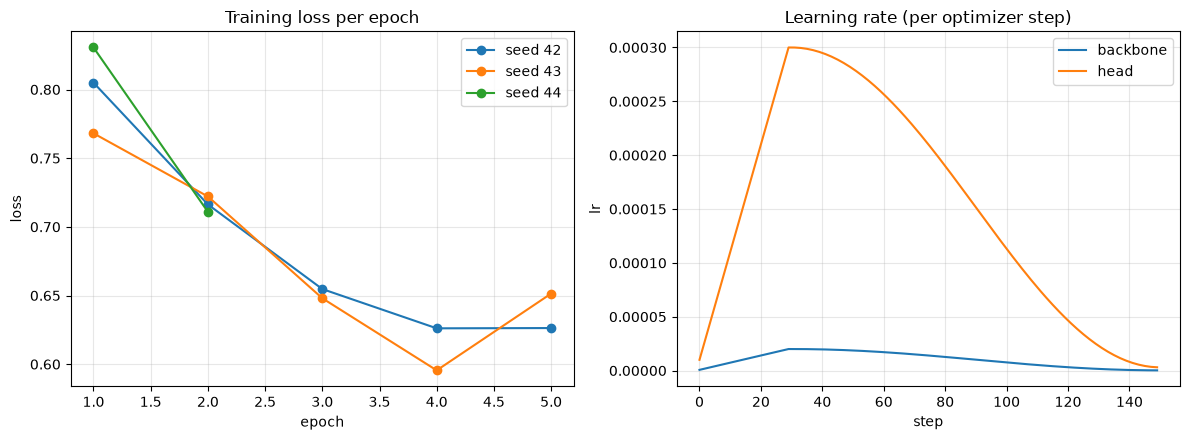

In [8]:
import matplotlib.pyplot as plt

# Training loss per epoch, copied from your earlier log
train_loss = {
    42: [0.8050, 0.7163, 0.6547, 0.6261, 0.6263],
    43: [0.7681, 0.7221, 0.6480, 0.5955, 0.6514],
    44: [0.8306, 0.7109],
}

# Learning rate schedule, rebuilt with the notebook's own scheduler
dl_len = len(pd.read_csv(CFG["train_csv"])) // CFG["batch_size"]   # drop_last batches
spe = dl_len // CFG["accum"]                                         # optimizer steps per epoch
params = [torch.nn.Parameter(torch.zeros(1)), torch.nn.Parameter(torch.zeros(1))]
dummy = torch.optim.AdamW([{"params":[params[0]], "lr":CFG["lr_backbone"]},
                           {"params":[params[1]], "lr":CFG["lr_head"]}])
sched = M.warmup_cosine(dummy, spe*CFG["warmup_epochs"], spe*CFG["epochs"])
lr_bb, lr_hd = [], []
for _ in range(spe*CFG["epochs"]):
    lr_bb.append(dummy.param_groups[0]["lr"]); lr_hd.append(dummy.param_groups[1]["lr"])
    dummy.step(); sched.step()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for s, l in train_loss.items():
    ax[0].plot(range(1, len(l)+1), l, marker="o", label=f"seed {s}")
ax[0].set(title="Training loss per epoch", xlabel="epoch", ylabel="loss"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(lr_bb, label="backbone"); ax[1].plot(lr_hd, label="head")
ax[1].set(title="Learning rate (per optimizer step)", xlabel="step", ylabel="lr"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(CFG["out_dir"]/"training_plots.png", dpi=150); plt.show()
